# Data Preparation for Machine Learning

This notebook provides a step-by-step guide to cleaning tree data from Grenoble in order to predict the planting year.

## Objective
Prepare the data to train a Machine Learning model that can predict missing tree planting years.

## Notebook Outline
1. Import libraries and load data  
2. Initial data exploration  
3. Data cleaning  
4. Save the data as a pickle file

## 1. Importing Libraries and Loading Data

We use several essential Python libraries for data analysis:
- pandas: for data manipulation  
- numpy: for numerical computations  
- matplotlib and seaborn: for visualization  
- sklearn: for preparing data for Machine Learning

In [17]:
#%pip install -r '../requirements.txt'
%conda init
%conda activate sklearn-env

# Libraries
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

no change     /home/alexia.gaudeul@Digital-Grenoble.local/miniconda3/condabin/conda
no change     /home/alexia.gaudeul@Digital-Grenoble.local/miniconda3/bin/conda
no change     /home/alexia.gaudeul@Digital-Grenoble.local/miniconda3/bin/activate
no change     /home/alexia.gaudeul@Digital-Grenoble.local/miniconda3/bin/deactivate
no change     /home/alexia.gaudeul@Digital-Grenoble.local/miniconda3/etc/profile.d/conda.sh
no change     /home/alexia.gaudeul@Digital-Grenoble.local/miniconda3/etc/fish/conf.d/conda.fish
no change     /home/alexia.gaudeul@Digital-Grenoble.local/miniconda3/shell/condabin/Conda.psm1
no change     /home/alexia.gaudeul@Digital-Grenoble.local/miniconda3/shell/condabin/conda-hook.ps1
no change     /home/alexia.gaudeul@Digital-Grenoble.local/miniconda3/lib/python3.14/site-packages/xontrib/conda.xsh
no change     /home/alexia.gaudeul@Digital-Grenoble.local/miniconda3/etc/profile.d/conda.csh
no change     /home/alexia.gaudeul@Digital-Grenoble.local/.bashrc
No action take

In [18]:
# Loading the Data
df = pd.read_csv('../arbres_grenoble_epsg4326.csv', sep=',', encoding='utf-8')

# Display the first few rows
print('Data preview:')
display(df.head())

# Dataset information
print('\nDataset information:')
display(df.info())

Data preview:


,elem_point_id,code,nom,genre,genre_desc,categorie,categorie_desc,sous_categorie,sous_categorie_desc,code_parent,...,diametrearbre,causeabattage,collectivite,stationmetro,hauteurarbre,portarbre,structure,forme,typenature,geo_point_2d
0,34835,ESP36318,AR36318,VEG,VEGETATION,ESP01,Arbre,ESP151,Arbre de voirie,ESP237,...,NaN,NaN,Grenoble Alpes Métropole,NaN,NaN,NaN,Métropole de Grenoble,NaN,NaN,"45.167098421885385,5.740131798404362"
1,34836,ESP36319,AR36319,VEG,VEGETATION,ESP01,Arbre,ESP151,Arbre de voirie,ESP237,...,NaN,NaN,Grenoble Alpes Métropole,NaN,NaN,NaN,Métropole de Grenoble,NaN,NaN,"45.16710682038838,5.740199792549315"
2,34837,ESP36320,AR36320,VEG,VEGETATION,ESP01,Arbre,ESP151,Arbre de voirie,ESP237,...,NaN,NaN,Grenoble Alpes Métropole,NaN,NaN,NaN,Métropole de Grenoble,NaN,NaN,"45.167115270975415,5.740265608803635"
3,34838,ESP36321,AR36321,VEG,VEGETATION,ESP01,Arbre,ESP151,Arbre de voirie,ESP237,...,NaN,NaN,Grenoble Alpes Métropole,NaN,NaN,NaN,Métropole de Grenoble,NaN,NaN,"45.16712715617142,5.740349032579623"
4,34839,ESP36322,AR36322,VEG,VEGETATION,ESP01,Arbre,ESP151,Arbre de voirie,ESP237,...,NaN,NaN,Grenoble Alpes Métropole,NaN,NaN,NaN,Métropole de Grenoble,NaN,NaN,"45.167144245872265,5.740471081600832"



Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 31670 entries, 0 to 31669
Data columns (total 38 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   elem_point_id          31670 non-null  int64  
 1   code                   31670 non-null  str    
 2   nom                    31670 non-null  str    
 3   genre                  31670 non-null  str    
 4   genre_desc             31670 non-null  str    
 5   categorie              31670 non-null  str    
 6   categorie_desc         31670 non-null  str    
 7   sous_categorie         31670 non-null  str    
 8   sous_categorie_desc    31670 non-null  str    
 9   code_parent            31670 non-null  str    
 10  code_parent_desc       31670 non-null  str    
 11  adr_secteur            31670 non-null  int64  
 12  bien_reference         31670 non-null  str    
 13  genre_bota             30859 non-null  str    
 14  espece                 29370 non-null  str 

None

In [19]:
df_traitch = df['traitementchenilles'].dropna()
df_traitch.value_counts()

traitementchenilles
Haute      1086
Moyenne     853
Basse       127
Name: count, dtype: int64

In [20]:
df['raisondeplantation'].value_counts()

raisondeplantation
Nouveau         2896
Remplacement     388
Existant           3
Name: count, dtype: int64

In [21]:
for i in df.columns:
    print(df[i].value_counts())

elem_point_id
34835    1
34836    1
34837    1
34838    1
34839    1
        ..
44741    1
44742    1
44841    1
44842    1
44982    1
Name: count, Length: 31670, dtype: int64
code
ESP36318    1
ESP36319    1
ESP36320    1
ESP36321    1
ESP36322    1
           ..
ESP40744    1
ESP40745    1
ESP40796    1
ESP40797    1
ESP40913    1
Name: count, Length: 31670, dtype: int64
nom
AR36318    1
AR36319    1
AR36320    1
AR36321    1
AR36322    1
          ..
AR40744    1
AR40745    1
AR40796    1
AR40797    1
AR40913    1
Name: count, Length: 31670, dtype: int64
genre
VEG    31670
Name: count, dtype: int64
genre_desc
VEGETATION    31670
Name: count, dtype: int64
categorie
ESP01    31670
Name: count, dtype: int64
categorie_desc
Arbre    31670
Name: count, dtype: int64
sous_categorie
ESP174    15222
ESP151    12473
ESP065     2475
ESP187     1500
Name: count, dtype: int64
sous_categorie_desc
Arbre d'espaces ouverts      15222
Arbre de voirie              12473
Arbre d'enceintes fermées     24

## 2. Initial Data Exploration

Before starting the cleaning process, it's crucial to understand our data:
- What columns are available?  
- What types of data do we have?  
- Are there any missing values?

In [22]:
# Descriptive Statistics
df.dtypes
# Analysis of Missing Values
x=df[df['anneedeplantation']==2000].isna().sum()/len(df[df['anneedeplantation']==2000])*100
print(x)

elem_point_id              0.000000
code                       0.000000
nom                        0.000000
genre                      0.000000
genre_desc                 0.000000
categorie                  0.000000
categorie_desc             0.000000
sous_categorie             0.000000
sous_categorie_desc        0.000000
code_parent                0.000000
code_parent_desc           0.000000
adr_secteur                0.000000
bien_reference             0.000000
genre_bota                 0.000000
espece                     0.496278
variete                   75.186104
stadededeveloppement       0.000000
equipe                   100.000000
remarques                 90.322581
anneedeplantation          0.000000
raisondeplantation       100.000000
traitementchenilles       95.037221
courrier                 100.000000
identifiantplu           100.000000
typeimplantationplu       57.568238
intituleprotectionplu    100.000000
anneeabattage            100.000000
essouchement             100

In [23]:
df[df['anneedeplantation']==1900]
df['anneedeplantation'].value_counts().index.sort_values()

Index([1900.0, 1924.0, 1944.0, 1950.0, 1955.0, 1959.0, 1960.0, 1964.0, 1965.0,
       1966.0, 1967.0, 1968.0, 1969.0, 1970.0, 1971.0, 1972.0, 1973.0, 1974.0,
       1975.0, 1976.0, 1977.0, 1978.0, 1979.0, 1980.0, 1981.0, 1982.0, 1983.0,
       1984.0, 1985.0, 1986.0, 1987.0, 1988.0, 1989.0, 1990.0, 1991.0, 1992.0,
       1993.0, 1994.0, 1995.0, 1996.0, 1997.0, 1998.0, 1999.0, 2000.0, 2001.0,
       2002.0, 2003.0, 2004.0, 2005.0, 2006.0, 2007.0, 2008.0, 2009.0, 2010.0,
       2011.0, 2012.0, 2013.0, 2014.0, 2015.0, 2016.0, 2017.0, 2018.0, 2019.0,
       2020.0, 2021.0, 2022.0, 2023.0, 2024.0],
      dtype='float64', name='anneedeplantation')

### Visualisation of missing values

<Axes: >

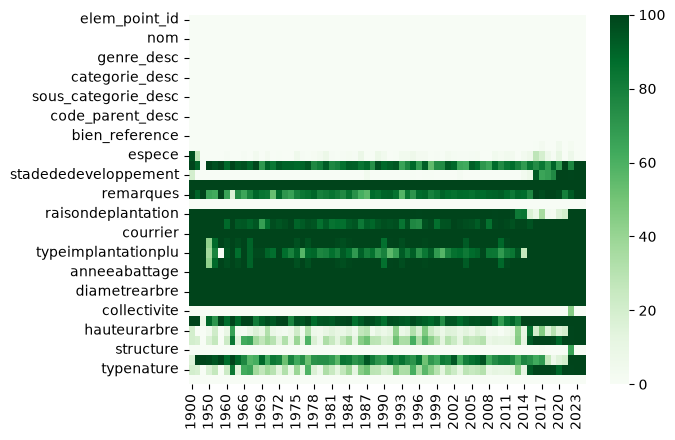

In [24]:
# Creation of a heatmap to visualize missing values
#sns.heatmap(df.isna())
percent_missing=pd.DataFrame()
for i in df['anneedeplantation'].value_counts().index.sort_values():
    percent_missing[i]=df[df['anneedeplantation']==int(i)].isna().sum()/len(df[df['anneedeplantation']==int(i)])*100

percent_missing

sns.heatmap(percent_missing, cmap='Greens')

## 3. Data Cleaning

### 3.1 After the initial analysis, we will:
1. Remove rows without a planting year **'annedeplantation'**
2. Drop columns that are irrelevant for prediction  
3. Extract geographic coordinates

In [25]:
# 1. Remove rows without a planting year **'annedeplantation'**

""" df = df[df['anneedeplantation'].notna()]

print(df['anneedeplantation'].isna().sum())

x=df.isna().sum()/len(df)*100
x = x.reset_index()
x = x[x[0] == 100]
todrop=list(x['index']) 

df = df.drop(columns=todrop)

todrop2 = ['genre','genre_desc','elem_point_id','code','nom','categorie','categorie_desc','bien_reference','collectivite','typenature']
df = df.drop(columns=todrop2)

 """
 
# remove also columns with only one unique value, all unique values, or no values, but be careful with important columns like 'geo_point_2d'

location=df["geo_point_2d"].copy()

todrop3 = df.loc[:, df.nunique().isin([1, len(df), 0])].columns

df = df.drop(columns=todrop3)
df["location"]=location



### 🔍 3.2 Cleaning Unnecessary Columns

We will:

- Remove columns with more than **40% missing values**  
- Remove columns that are **too specific** (e.g., unique identifiers), which don't provide useful information for machine learning  
- Remove columns that contain redundant or unhelpful information

In [26]:
# 2. Extract geographic coordinates

print(df.columns)
#%conda install geopy
import json
from geopy.distance import geodesic

print(df["location"].head())

#df["location"]= df['location'].apply(lambda x: (json.loads(x)['coordinates']))
df["location"] = df["location"].apply(lambda x: x.split(","))
print(df["location"].head())
df["latitude"] = df["location"].apply(lambda x: x[0])
print(df["latitude"].head())
df["longitude"] = df["location"].apply(lambda x: x[1])
print(df["longitude"].head())
print(df["location"])


mask = (
    df["latitude"].str.strip().eq("") |
    df["longitude"].str.strip().eq("") |
    df["latitude"].isnull() |
    df["longitude"].isnull()
)
df.loc[mask, ["location", "latitude", "longitude"]]

Index(['sous_categorie', 'sous_categorie_desc', 'code_parent',
       'code_parent_desc', 'adr_secteur', 'genre_bota', 'espece', 'variete',
       'stadededeveloppement', 'remarques', 'anneedeplantation',
       'raisondeplantation', 'traitementchenilles', 'identifiantplu',
       'typeimplantationplu', 'intituleprotectionplu', 'collectivite',
       'stationmetro', 'hauteurarbre', 'portarbre', 'structure', 'forme',
       'typenature', 'location'],
      dtype='str')
0    45.167098421885385,5.740131798404362
1     45.16710682038838,5.740199792549315
2    45.167115270975415,5.740265608803635
3     45.16712715617142,5.740349032579623
4    45.167144245872265,5.740471081600832
Name: location, dtype: str
0    [45.167098421885385, 5.740131798404362]
1     [45.16710682038838, 5.740199792549315]
2    [45.167115270975415, 5.740265608803635]
3     [45.16712715617142, 5.740349032579623]
4    [45.167144245872265, 5.740471081600832]
Name: location, dtype: object
0    45.167098421885385
1     45.16

,location,latitude,longitude
27315,"[, ]",,


In [27]:

# transform latitude and longitude to float
df["latitude"] = pd.to_numeric(df["latitude"].str.strip(), errors="coerce")
df["longitude"] = pd.to_numeric(df["longitude"].str.strip(), errors="coerce")


print(df["latitude"].head())
print(df["longitude"].head())

0    45.167098
1    45.167107
2    45.167115
3    45.167127
4    45.167144
Name: latitude, dtype: float64
0    5.740132
1    5.740200
2    5.740266
3    5.740349
4    5.740471
Name: longitude, dtype: float64


In [28]:
# 3. Remove overly specific columns, such as the 'elem_point_id' column

display(df.info())

df = df.drop('location', axis=1).copy()

display(df.info())


<class 'pandas.DataFrame'>
RangeIndex: 31670 entries, 0 to 31669
Data columns (total 26 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   sous_categorie         31670 non-null  str    
 1   sous_categorie_desc    31670 non-null  str    
 2   code_parent            31670 non-null  str    
 3   code_parent_desc       31670 non-null  str    
 4   adr_secteur            31670 non-null  int64  
 5   genre_bota             30859 non-null  str    
 6   espece                 29370 non-null  str    
 7   variete                4599 non-null   str    
 8   stadededeveloppement   27496 non-null  str    
 9   remarques              5312 non-null   str    
 10  anneedeplantation      29526 non-null  float64
 11  raisondeplantation     3287 non-null   str    
 12  traitementchenilles    2066 non-null   str    
 13  identifiantplu         587 non-null    float64
 14  typeimplantationplu    4968 non-null   str    
 15  intituleprote

None

<class 'pandas.DataFrame'>
RangeIndex: 31670 entries, 0 to 31669
Data columns (total 25 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   sous_categorie         31670 non-null  str    
 1   sous_categorie_desc    31670 non-null  str    
 2   code_parent            31670 non-null  str    
 3   code_parent_desc       31670 non-null  str    
 4   adr_secteur            31670 non-null  int64  
 5   genre_bota             30859 non-null  str    
 6   espece                 29370 non-null  str    
 7   variete                4599 non-null   str    
 8   stadededeveloppement   27496 non-null  str    
 9   remarques              5312 non-null   str    
 10  anneedeplantation      29526 non-null  float64
 11  raisondeplantation     3287 non-null   str    
 12  traitementchenilles    2066 non-null   str    
 13  identifiantplu         587 non-null    float64
 14  typeimplantationplu    4968 non-null   str    
 15  intituleprote

None

In [29]:
for col in df.columns:
     print(f"\n{col}")
     print(df[col].value_counts())
     print(df[col].dtype)


sous_categorie
sous_categorie
ESP174    15222
ESP151    12473
ESP065     2475
ESP187     1500
Name: count, dtype: int64
str

sous_categorie_desc
sous_categorie_desc
Arbre d'espaces ouverts      15222
Arbre de voirie              12473
Arbre d'enceintes fermées     2475
Bois semi naturel             1500
Name: count, dtype: int64
str

code_parent
code_parent
ESP995      369
ESP31821    338
ESP495      302
ESP761      269
ESP720      265
           ... 
ESP43443      1
ESP803        1
ESP1082       1
ESP650        1
ESP43514      1
Name: count, Length: 1505, dtype: int64
str

code_parent_desc
code_parent_desc
Prc Echangeurs Bastion St Roch    369
Le Bastion zone boisée            338
Cimetière St Roch                 302
Grande pelouse butte des pins     269
Prc Echangeurs Valmy Gallieni     265
                                 ... 
Park Bastille Glacis                1
R Expilly Pl J Achard               1
Av J O nord Mantayer 140 RIA        1
R Valles ang C Genin                1
Ec E

In [30]:
df['adr_secteur'] = df['adr_secteur'].astype(str)
df['identifiantplu'] = df['identifiantplu'].astype(str)

# drop les colonnes qui sont les memes que d'autres colonnes

df.drop(columns=['code_parent', 'sous_categorie'], inplace=True)    

df.dtypes

/tmp/ipykernel_89185/4293006848.py:6: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(columns=['code_parent', 'sous_categorie'], inplace=True)


sous_categorie_desc          str
code_parent_desc             str
adr_secteur                  str
genre_bota                   str
espece                       str
variete                      str
stadededeveloppement         str
remarques                    str
anneedeplantation        float64
raisondeplantation           str
traitementchenilles          str
identifiantplu               str
typeimplantationplu          str
intituleprotectionplu        str
collectivite                 str
stationmetro                 str
hauteurarbre                 str
portarbre                    str
structure                    str
forme                        str
typenature                   str
latitude                 float64
longitude                float64
dtype: object

In [ ]:
#je veux recoder les missing values en 'Unknown'
cat_cols = df.select_dtypes(include=["object", "string", "category"]).columns
df[cat_cols] = df[cat_cols].astype("str").fillna("Unknown")

# Vérification après le recodage des missing values
df.isnull().sum()

# je veux aussi recoder les categories dans les str variables avec moins de 30 representant  en "Rare"
for col in df.select_dtypes(include='str').columns:
    value_counts = df[col].value_counts()
    rare_values = value_counts[value_counts <= 30].index
    df[col] = df[col].replace(rare_values, 'Rare')
    
# Vérification finale des types de données
df.dtypes

for col in df.columns:
     print(f"\n{col}")
     print(df[col].value_counts())
     print(df[col].dtype)
     print(df[col].nunique())
    

/tmp/ipykernel_89185/3122932168.py:9: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include='object').columns:



sous_categorie_desc
sous_categorie_desc
Arbre d'espaces ouverts      15222
Arbre de voirie              12473
Arbre d'enceintes fermées     2475
Bois semi naturel             1500
Name: count, dtype: int64
str
4

code_parent_desc
code_parent_desc
Rare                              14497
Prc Echangeurs Bastion St Roch      369
Le Bastion zone boisée              338
Cimetière St Roch                   302
Grande pelouse butte des pins       269
                                  ...  
Qu de France                         31
Sq Mutualité ang Chanrion            31
Jard Hoche cour du mikado            31
R G Lafourcade Terrain Blanc         31
R G Tonnelier Cocat Fernandat        31
Name: count, Length: 272, dtype: int64
str
272

adr_secteur
adr_secteur
6        6916
5        6676
2        6028
3        4185
4        4112
1        3368
38309     180
38151      92
38421      68
38249      36
Rare        9
Name: count, dtype: int64
str
11

genre_bota
genre_bota
Acer          5026
Platanus   

## 4. Save to data to a pickle file

In [32]:
# Save to data to a pickle file

df.to_pickle('arbres_clean_Alexia.pkl')

## Conclusion

We have completed several important cleaning steps:
1. Removed irrelevant columns or those with too many missing values  
2. Extracted geographic coordinates  

The data is now ready for the next steps of the project.